# BAI_MAU_GiuaKy.ipynb — Notebook giải mẫu (luyện tập)
Bám theo cấu trúc **Đề 1** (laptop / khách sạn). Dùng dữ liệu giả lập cùng thư mục `Data/`.

**Mục tiêu:** làm quen khung code, khi thi thật chỉ cần đổi tên cột/tên file theo đề thật.

## Câu 1. Thu thập và trích xuất dữ liệu web (3.0đ)

In [1]:
import os
import re
import pandas as pd
from bs4 import BeautifulSoup

DATA_DIR = "Data/Chuong2/pages"
OUT1_DIR = "Cau1"
os.makedirs(OUT1_DIR, exist_ok=True)


### a. (1.0đ) Đọc page1.html, in tên 4 sản phẩm

In [2]:
with open(os.path.join(DATA_DIR, "page1.html"), encoding="utf-8") as f:
    soup1 = BeautifulSoup(f, "html5lib")   # bat buoc html5lib

products_p1 = soup1.select(".product-card")
for p in products_p1:
    ten = p.find(class_="ten-sp").get_text(strip=True)
    print(ten)


Laptop Dell Inspiron 15
Laptop Asus Vivobook 14
Laptop HP Pavilion 14
Laptop Lenovo IdeaPad Slim 3


### b. (1.0đ) Duyệt cả 2 file, bóc 4 trường, ghi san_pham_tho.csv (đúng 8 dòng)

In [3]:
def parse_page(filepath):
    with open(filepath, encoding="utf-8") as f:
        soup = BeautifulSoup(f, "html5lib")
    rows = []
    for card in soup.select(".product-card"):
        ten_sp = card.find(class_="ten-sp").get_text(strip=True)
        gia_goc = card.find(class_="gia-goc").get_text(strip=True)
        gia_ban = card.find(class_="gia-ban").get_text(strip=True)
        km_tag = card.find(class_="khuyen-mai")
        khuyen_mai = km_tag.get_text(strip=True) if km_tag else ""   # khong co the -> de rong
        rows.append({
            "ten_sp": ten_sp,
            "gia_goc": gia_goc,
            "gia_ban": gia_ban,
            "khuyen_mai": khuyen_mai,
        })
    return rows

all_rows = []
for fname in ["page1.html", "page2.html"]:
    all_rows.extend(parse_page(os.path.join(DATA_DIR, fname)))

df_tho = pd.DataFrame(all_rows, columns=["ten_sp", "gia_goc", "gia_ban", "khuyen_mai"])
assert len(df_tho) == 8, f"Phai dung 8 dong, dang co {len(df_tho)}"
df_tho.to_csv(os.path.join(OUT1_DIR, "san_pham_tho.csv"), index=False, encoding="utf-8")
df_tho


,ten_sp,gia_goc,gia_ban,khuyen_mai
0,Laptop Dell Inspiron 15,15.990.000,13.490.000,Giảm 500k khi mua kèm chuột
1,Laptop Asus Vivobook 14,12.500.000,10.990.000,
2,Laptop HP Pavilion 14,17.200.000,15.800.000,Tặng balo laptop
3,Laptop Lenovo IdeaPad Slim 3,11.990.000,10.490.000,
4,Laptop Acer Aspire 7,19.990.000,16.990.000,Giảm thêm 10% cho SV
5,Laptop MSI Modern 14,14.500.000,12.990.000,
6,Laptop Macbook Air M1,22.990.000,20.490.000,Tặng túi chống sốc
7,Laptop Gigabyte G5,25.990.000,22.500.000,


### c. (1.0đ) Từ san_pham_tho.csv, tạo san_pham_sach.csv (giá int, ty_le_giam)

In [4]:
def parse_vnd(s):
    # "15.990.000" -> 15990000 (bo dau phan cach nghin)
    digits = re.sub(r"[^\d]", "", str(s))
    return int(digits) if digits else 0

df_tho = pd.read_csv(os.path.join(OUT1_DIR, "san_pham_tho.csv"), encoding="utf-8", keep_default_na=False)

df_sach = pd.DataFrame()
df_sach["ten_sp"] = df_tho["ten_sp"]
df_sach["gia_goc_vnd"] = df_tho["gia_goc"].apply(parse_vnd)
df_sach["gia_ban_vnd"] = df_tho["gia_ban"].apply(parse_vnd)
df_sach["khuyen_mai"] = df_tho["khuyen_mai"].apply(
    lambda x: "Không có khuyến mại" if str(x).strip() == "" else x
)
df_sach["ty_le_giam"] = df_sach.apply(
    lambda r: round((r["gia_goc_vnd"] - r["gia_ban_vnd"]) / r["gia_goc_vnd"] * 100, 2),
    axis=1,
)
df_sach.to_csv(os.path.join(OUT1_DIR, "san_pham_sach.csv"), index=False, encoding="utf-8")
df_sach


,ten_sp,gia_goc_vnd,gia_ban_vnd,khuyen_mai,ty_le_giam
0,Laptop Dell Inspiron 15,15990000,13490000,Giảm 500k khi mua kèm chuột,15.63
1,Laptop Asus Vivobook 14,12500000,10990000,Không có khuyến mại,12.08
2,Laptop HP Pavilion 14,17200000,15800000,Tặng balo laptop,8.14
3,Laptop Lenovo IdeaPad Slim 3,11990000,10490000,Không có khuyến mại,12.51
4,Laptop Acer Aspire 7,19990000,16990000,Giảm thêm 10% cho SV,15.01
5,Laptop MSI Modern 14,14500000,12990000,Không có khuyến mại,10.41
6,Laptop Macbook Air M1,22990000,20490000,Tặng túi chống sốc,10.87
7,Laptop Gigabyte G5,25990000,22500000,Không có khuyến mại,13.43


## Câu 2. Tiền xử lý và khám phá dữ liệu văn bản (7.0đ)

In [5]:
from underthesea import word_tokenize

DATA3_DIR = "Data/Chuong3"
OUT2_DIR = "Cau2"
os.makedirs(OUT2_DIR, exist_ok=True)


### a. (1.0-1.5đ) buoc1.csv — lowercase, xóa HTML, xóa URL, xóa số, chuẩn hóa khoảng trắng
**Giữ lại** emoji/emoticon/dấu câu ở bước này.

In [6]:
def buoc1_clean(text):
    text = text.lower()
    text = BeautifulSoup(text, "html.parser").get_text()          # xoa the HTML
    text = re.sub(r"https?://\S+|www\.\S+", "", text)              # xoa URL
    text = re.sub(r"\d+", "", text)                                # xoa chu so
    text = re.sub(r"\s+", " ", text).strip()                       # chuan hoa khoang trang
    return text

df_raw = pd.read_csv(os.path.join(DATA3_DIR, "reviews_raw.csv"), encoding="utf-8")
df_b1 = pd.DataFrame()
df_b1["id"] = df_raw["id"]
df_b1["review_buoc1"] = df_raw["review"].apply(buoc1_clean)
df_b1.to_csv(os.path.join(OUT2_DIR, "buoc1.csv"), index=False, encoding="utf-8")
df_b1


,id,review_buoc1
0,1,khách sạn rất đẹp và sạch sẽ 😍. thủ tục check-...
1,2,phòng ok nhưng hơi ồn vào buổi tối :( . giá vn...
2,3,"view biển siêu đẹp 😊😊, bể bơi sạch. sẽ quay lạ..."
3,4,"nhân viên phục vụ chưa chuyên nghiệp, chờ chec..."
4,5,"bữa sáng phong phú, đồ ăn ngon miệng 😍. wifi h..."
5,6,"phòng rộng, decor hiện đại, rất đáng tiền so v..."
6,7,"vị trí gần biển, đi bộ phút. checkin dễ dàng, ..."
7,8,"chất lượng dịch vụ tệ, phòng bẩn, không như ản..."
8,9,"bể bơi vô cực view cực đẹp 😍, buổi tối có nhạc..."
9,10,giá hơi cao nhưng chất lượng phòng tương xứng....


### b. (1.0-1.5đ) buoc2.csv — thay emoji/emoticon + chuẩn hóa từ viết tắt, RỒI mới xóa dấu câu
**Bẫy quan trọng:** chuẩn hóa `check-in` -> `checkin` PHẢI làm trước khi xóa dấu câu, nếu không dấu `-` mất trước sẽ vỡ thành 2 token `check` và `in`.

In [7]:
import string

def load_map(csv_path):
    m = pd.read_csv(csv_path, encoding="utf-8")
    return dict(zip(m.iloc[:, 0].astype(str), m.iloc[:, 1].astype(str)))

emoji_map = load_map(os.path.join(DATA3_DIR, "emoji_map.csv"))
abbr_map = load_map(os.path.join(DATA3_DIR, "tu_dien_chuan_hoa.csv"))

# Sap xep key dai truoc de tranh thay the nham (vd ":((" phai thay truoc ":(")
def apply_map(text, mapping):
    for key in sorted(mapping.keys(), key=len, reverse=True):
        text = text.replace(key, " " + mapping[key] + " ")
    return text

def buoc2_clean(text):
    text = apply_map(text, emoji_map)     # thay emoji/emoticon truoc
    text = apply_map(text, abbr_map)      # chuan hoa viet tat (check-in -> checkin) TRUOC khi xoa dau cau
    text = text.translate(str.maketrans("", "", string.punctuation))  # xoa dau cau
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_b1 = pd.read_csv(os.path.join(OUT2_DIR, "buoc1.csv"), encoding="utf-8")
df_b2 = pd.DataFrame()
df_b2["id"] = df_b1["id"]
df_b2["review_buoc2"] = df_b1["review_buoc1"].apply(buoc2_clean)
df_b2.to_csv(os.path.join(OUT2_DIR, "buoc2.csv"), index=False, encoding="utf-8")
df_b2


,id,review_buoc2
0,1,khách sạn rất đẹp và sạch sẽ yeuthich thủ tục ...
1,2,phòng ok nhưng hơi ồn vào buổi tối khonghailon...
2,3,view biển siêu đẹp hailong hailong bể bơi sạch...
3,4,nhân viên phục vụ chưa chuyên nghiệp chờ check...
4,5,bữa sáng phong phú đồ ăn ngon miệng yeuthich w...
5,6,phòng rộng decor hiện đại rất đáng tiền so với...
6,7,vị trí gần biển đi bộ phút checkin dễ dàng lễ ...
7,8,chất lượng dịch vụ tệ phòng bẩn không như ảnh ...
8,9,bể bơi vô cực view cực đẹp yeuthich buổi tối c...
9,10,giá hơi cao nhưng chất lượng phòng tương xứng ...


### c. (1.0-1.5đ) buoc3.csv — tách từ tiếng Việt + xóa stopword

In [8]:
with open(os.path.join(DATA3_DIR, "stopwords.txt"), encoding="utf-8") as f:
    stopwords = set(line.strip() for line in f if line.strip())

def buoc3_tokenize(text):
    tokenized = word_tokenize(text, format="text")   # bat buoc format="text"
    tokens = [t for t in tokenized.split() if t not in stopwords]
    return " ".join(tokens)

df_b2 = pd.read_csv(os.path.join(OUT2_DIR, "buoc2.csv"), encoding="utf-8")
df_b3 = pd.DataFrame()
df_b3["id"] = df_b2["id"]
df_b3["tokens"] = df_b2["review_buoc2"].apply(buoc3_tokenize)
df_b3.to_csv(os.path.join(OUT2_DIR, "buoc3.csv"), index=False, encoding="utf-8")
df_b3


,id,tokens
0,1,khách_sạn đẹp sạch_sẽ yeuthich thủ_tục checkin...
1,2,phòng ok ồn tối khonghailong giá đồng đêm hợp_...
2,3,view biển siêu đẹp hailong hailong bể bơi sạch...
3,4,nhân_viên phục_vụ chưa chuyên_nghiệp chờ check...
4,5,bữa sáng phong_phú đồ_ăn ngon_miệng yeuthich w...
5,6,phòng rộng decor hiện_đại đáng tiền so giá giớ...
6,7,vị_trí gần biển đi bộ phút checkin dễ_dàng lễ_...
7,8,chất_lượng dịch_vụ tệ phòng bẩn như ảnh quảng_...
8,9,bể bơi vô_cực view cực đẹp yeuthich tối nhạc s...
9,10,giá cao chất_lượng phòng tương_xứng nhân_viên ...


### d. (1.0-1.5đ) tan_suat_top10.csv — tần suất unigram, sort giảm dần theo tần suất,
**tie-break tăng dần theo token**

In [9]:
from collections import Counter

df_b3 = pd.read_csv(os.path.join(OUT2_DIR, "buoc3.csv"), encoding="utf-8", keep_default_na=False)
all_tokens = []
for line in df_b3["tokens"]:
    all_tokens.extend(str(line).split())

counter = Counter(all_tokens)
# sort: tan_suat giam dan, token tang dan khi bang nhau
items_sorted = sorted(counter.items(), key=lambda x: (-x[1], x[0]))
top10 = items_sorted[:10]

df_top10 = pd.DataFrame(top10, columns=["token", "tan_suat"])
df_top10.to_csv(os.path.join(OUT2_DIR, "tan_suat_top10.csv"), index=False, encoding="utf-8")
df_top10


,token,tan_suat
0,checkin,4
1,hailong,4
2,phòng,4
3,giá,3
4,nhân_viên,3
5,yeuthich,3
6,đẹp,3
7,biển,2
8,bơi,2
9,bể,2


### e. (1.0đ) Biểu đồ cột ngang + WordCloud + nhận xét

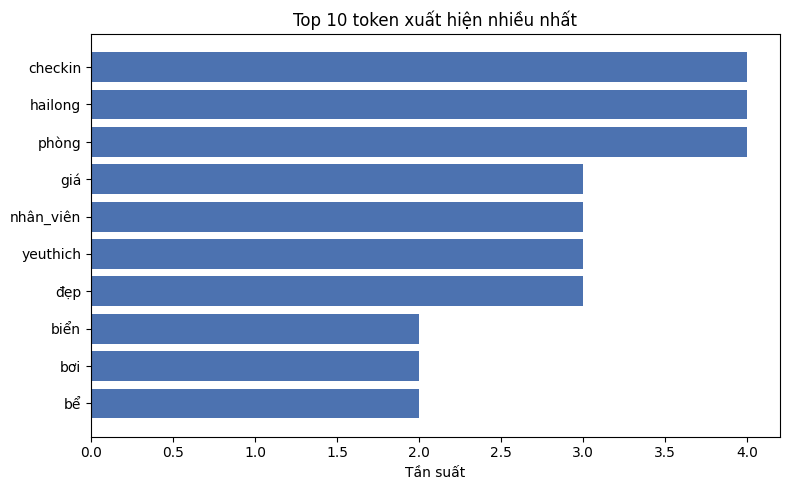

In [10]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

df_top10 = pd.read_csv(os.path.join(OUT2_DIR, "tan_suat_top10.csv"), encoding="utf-8")

# Bieu do cot NGANG (barh), khong phai cot dung
plt.figure(figsize=(8, 5))
plt.barh(df_top10["token"][::-1], df_top10["tan_suat"][::-1], color="#4C72B0")
plt.xlabel("Tần suất")
plt.title("Top 10 token xuất hiện nhiều nhất")
plt.tight_layout()
plt.savefig(os.path.join(OUT2_DIR, "bieu_do_top10.png"))
plt.show()


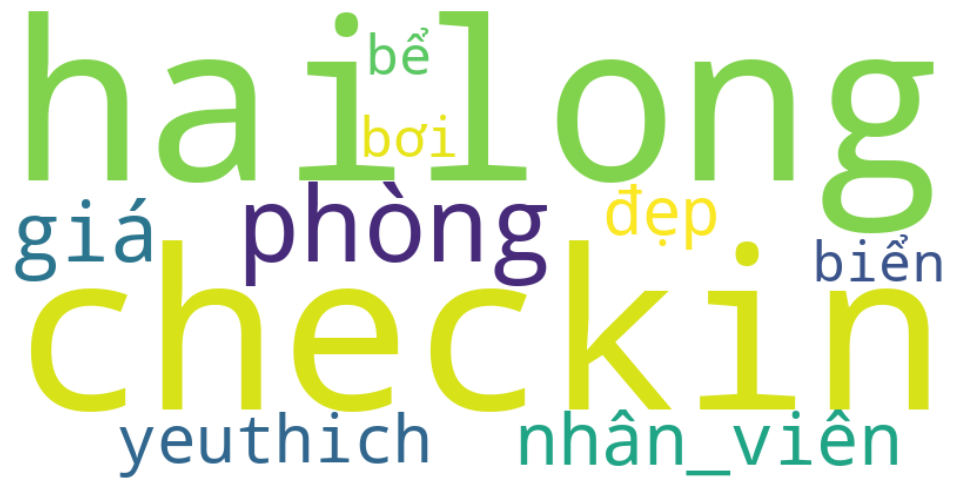

In [11]:
freq_dict = dict(zip(df_top10["token"], df_top10["tan_suat"]))
# Neu can font tieng Viet dung, truyen font_path=... toi 1 file .ttf co dau tieng Viet
wc = WordCloud(width=800, height=400, background_color="white")
wc.generate_from_frequencies(freq_dict)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT2_DIR, "wordcloud.png"))
plt.show()


In [12]:
# Nhan xet phai bam so lieu, KHONG suy dien thanh phan tich cam xuc
top_token_1, top_freq_1 = df_top10.iloc[0]["token"], df_top10.iloc[0]["tan_suat"]
top_token_2, top_freq_2 = df_top10.iloc[1]["token"], df_top10.iloc[1]["tan_suat"]

nhan_xet = (
    f"1. Token '{top_token_1}' xuat hien nhieu nhat voi tan suat {top_freq_1} lan, "
    f"cho thay day la tu khoa noi bat nhat trong tap du lieu.\n"
    f"2. Token '{top_token_2}' xep thu hai voi tan suat {top_freq_2} lan, "
    f"cung thuoc nhom tu duoc nguoi dung de cap thuong xuyen trong danh gia.\n"
)
with open(os.path.join(OUT2_DIR, "nhan_xet.txt"), "w", encoding="utf-8") as f:
    f.write(nhan_xet)

print(nhan_xet)


1. Token 'checkin' xuat hien nhieu nhat voi tan suat 4 lan, cho thay day la tu khoa noi bat nhat trong tap du lieu.
2. Token 'hailong' xep thu hai voi tan suat 4 lan, cung thuoc nhom tu duoc nguoi dung de cap thuong xuyen trong danh gia.

